# Emissionslinien von H-II-Regionen

Das Notebook lädt alle SDSS-DR17-Spektren, deren Fasern auf H-II-Regionen der Spiralgalaxie M 101 liegen, passt die Emissionslinien selbst mit Gaußprofilen an und bestimmt daraus Geschwindigkeit, Elektronendichte ([S II]-Dublett), Staubextinktion (Balmer-Dekrement) und Sauerstoffhäufigkeit (Kalibrierungen N2 und O3N2 von Pettini & Pagel). Ein BPT-Diagramm vor 20 000 SDSS-Galaxien zeigt, was das Gas ionisiert, die Häufigkeit gegen den Abstand vom Zentrum ergibt den Metallizitätsgradienten der Scheibe, und die eigenen Linienflüsse werden mit der SDSS-Pipeline und dem MPA-JHU-Katalog verglichen.

Was verraten ein paar helle Linien im Spektrum einer Gaswolke über die Sterne, die sie zum Leuchten bringen, und über die chemische Geschichte ihrer Galaxie?

#### **Hintergrund**

Wo in einer Galaxie gerade Sterne entstehen, leuchten H-II-Regionen: Gaswolken, die von jungen, heißen Sternen zum Leuchten gebracht werden, wie der Orionnebel in der Milchstraße. Ihr Spektrum besteht aus wenigen hellen Linien, und aus deren Verhältnissen lässt sich erstaunlich viel ablesen: wie dicht und wie staubig das Gas ist, ob junge Sterne oder ein schwarzes Loch es ionisieren, und wie viel Sauerstoff es enthält. Der Sauerstoff wurde in früheren Generationen von Sternen erbrütet; seine Häufigkeit ist deshalb ein Gedächtnis der chemischen Geschichte der Galaxie.

Dieselben Linien sind eines der wichtigsten Werkzeuge der Galaxienforschung. Mit dem BPT-Diagramm aus vier Linien trennt man in Durchmusterungen mit Hunderttausenden von Spektren Galaxien mit Sternentstehung von solchen mit aktivem Kern. Und der Abfall der Häufigkeit vom Zentrum nach außen, der Metallizitätsgradient, zeigt, dass Scheibengalaxien von innen nach außen gewachsen sind. Dieses Notebook misst alles selbst an der Spiralgalaxie M 101, auf deren H-II-Regionen der Sloan Digital Sky Survey (SDSS) zufällig Dutzende Fasern gesetzt hat: Die Software zur Zielauswahl hielt die hellen Knoten in den Armen für eigene Galaxien.

Landkarte:

- **Daten**
  - Die Galaxie und ihre SDSS-Spektren (Schritt 1): 57 Fasern auf M 101, 50 davon auf Gas der Galaxie.
- **Reduktion**
  - Linienfits (Schritt 2): Gaußprofile für acht Linien in 55 Spektren; gesättigte Linien werden verworfen.
- **Eigene Messung**
  - Dichte und Staub (Schritt 3): etwa 34 Elektronen pro cm³, der Staub schluckt die Hälfte des Hα-Lichts.
  - Das BPT-Diagramm (Schritt 4): Fast alle Regionen werden von jungen Sternen ionisiert.
- **Modell und Fit**
  - Der Metallizitätsgradient (Schritt 5): Die Sauerstoffhäufigkeit fällt um 0.02 dex pro kpc.
- **Eigene Messung gegen den Katalog**
  - Vergleich mit SDSS und MPA-JHU (Schritt 6): gleiche Linienverhältnisse, aber verschiedene Flusseichung und Häufigkeitsskalen.

Verwandte Notebooks: Bilder und Profile einer Spiralgalaxie in [Photometrie einer Galaxie](https://github.com/deltorobarba/science/blob/main/astro/galaxies_photometry.ipynb), die Rotation von Spiralgalaxien in [Rotationskurven und Dunkle Materie](https://github.com/deltorobarba/science/blob/main/astro/galaxies_rotationcurves.ipynb).

#### **Theorie**

##### *1. H-II-Regionen*

Junge, massereiche Sterne (Spektraltyp O und frühe B) strahlen so viele Photonen mit mehr als 13.6 eV ab, dass sie das Wasserstoffgas um sich herum vollständig ionisieren. Es entsteht eine **H-II-Region** (H II heißt ionisierter Wasserstoff), eine leuchtende Gaswolke von einigen bis einigen hundert Parsec Größe, etwa 10 000 K heiß und mit einigen bis einigen hundert Elektronen pro Kubikzentimeter. Sie leuchtet nur, solange die Sterne leben, also einige Millionen Jahre; H-II-Regionen markieren deshalb die Orte, an denen gerade Sterne entstehen.

##### *2. Emissionslinien und ihre Messung*

Das Spektrum besteht aus wenigen hellen Linien auf einem schwachen Kontinuum:
- **Rekombinationslinien** des Wasserstoffs (Hα bei 6563 Å, Hβ bei 4861 Å): Fängt ein Proton ein Elektron ein, kaskadiert das Elektron über feste Wege nach unten; das Verhältnis der Linien ist durch die Atomphysik festgelegt.
- **Verbotene Linien** von Sauerstoff, Stickstoff und Schwefel ([O III] 5007 Å, [N II] 6584 Å, [S II] 6717/6731 Å): Stöße mit Elektronen regen die Ionen an; die angeregten Zustände sind langlebig und zerfallen nur, weil das Gas so dünn ist, dass kein weiterer Stoß sie vorher abregt. Auf der Erde sieht man diese Linien nicht, daher die eckigen Klammern.

Eine Linie mit **Gaußprofil** der Höhe $A$, Mitte $\lambda_c$ und Breite $\sigma$ hat den **Fluss** $F = A\,\sigma\sqrt{2\pi}$, die Fläche unter der Kurve. Linien, die nahe beieinanderliegen, werden gemeinsam angepasst, mit einer Rotverschiebung $z$ und einer Breite pro Gruppe auf einem linearen Kontinuum. Die Mitte jeder Linie ist $\lambda_c = \lambda_0(1 + z)$, die Geschwindigkeit entlang der Sichtlinie $v = cz$.

##### *3. Staub und das Balmer-Dekrement*

Ohne Staub ist das Verhältnis Hα/Hβ, das **Balmer-Dekrement**, durch die Rekombinationskaskade festgelegt: 2.86 bei $T = 10^4$ K (**Fall B**: das Gas ist für die Lyman-Linien undurchsichtig). Staub schwächt blaues Licht stärker als rotes (**Rötung**), Hβ also stärker als Hα, und das Verhältnis steigt. Mit der **Extinktionskurve** von Cardelli, Clayton & Mathis (1989), $k(\text{H}\beta) = 3.61$ und $k(\text{H}\alpha) = 2.53$, ist die Rötung
$$E(B-V) = \frac{2.5}{k(\text{H}\beta) - k(\text{H}\alpha)} \log_{10}\frac{(\text{H}\alpha/\text{H}\beta)_\text{beob}}{2.86} .$$
Die **Extinktion** im V-Band, die Abschwächung in Magnituden, ist $A_V = 3.1\,E(B-V)$.

##### *4. Die Elektronendichte aus [S II]*

Die beiden oberen Niveaus des [S II]-Dubletts liegen fast auf derselben Energie, zerfallen aber verschieden schnell. Ist das Gas sehr dünn, endet jede Anregung durch einen Stoß in einem Photon, und das Verhältnis $R = F(6717)/F(6731)$ ist etwa 1.45. Ist das Gas dicht, regen Stöße die Niveaus vorher wieder ab, und $R$ sinkt auf etwa 0.43. Dazwischen hängt $R$ von der **Elektronendichte** $n_e$ ab; Sanders et al. (2016) beschreiben das bei $10^4$ K mit
$$R(n_e) = a\,\frac{b + n_e}{c + n_e}, \qquad a = 0.4315,\; b = 2107,\; c = 627.1\ \text{cm}^{-3},\qquad n_e = \frac{c R - a b}{a - R} .$$
Nahe 1.45 wird der Nenner klein; kleine Fehler in $R$ ergeben dort große Fehler in $n_e$. Das Dublett misst gut zwischen etwa 50 und 5000 cm⁻³.

##### *5. Das BPT-Diagramm*

Baldwin, Phillips & Terlevich (1981) tragen $\log([\text{O III}]\,5007/\text{H}\beta)$ gegen $\log([\text{N II}]\,6584/\text{H}\alpha)$ auf. Jedes Verhältnis vergleicht Linien fast derselben Wellenlänge, deshalb ändert Staub es kaum. Junge Sterne haben ein weiches Spektrum, das bei 54 eV abbricht. Ein **aktiver Galaxienkern** (AGN, ein Akkretionsfluss um ein supermassereiches schwarzes Loch) strahlt ein hartes Spektrum bis ins Röntgengebiet; seine Photonen heizen eine ausgedehnte, teilweise ionisierte Zone, in der viel [N II] und [O III] entsteht. AGN liegen deshalb rechts oben. Zwei Trennlinien teilen das Diagramm, mit $x = \log([\text{N II}]/\text{H}\alpha)$ und $y = \log([\text{O III}]/\text{H}\beta)$:
$$y = \frac{0.61}{x - 0.05} + 1.30 \ \text{(Kauffmann et al. 2003)},\qquad y = \frac{0.61}{x - 0.47} + 1.19 \ \text{(Kewley et al. 2001)} .$$
Unter der ersten liegt reine Sternentstehung, über der zweiten AGN, dazwischen Mischformen. **LINER** sind Kerne mit schwacher, niedrig ionisierter Emission.

##### *6. Sauerstoffhäufigkeit und Gradient*

Die Häufigkeit des Sauerstoffs wird als $12 + \log_{10}(\text{O/H})$ angegeben; die Sonne hat 8.69 (Asplund et al. 2009), und 0.1 dex sind 26 % mehr oder weniger Sauerstoff. Mehr Metalle kühlen das Gas besser; bei hoher Häufigkeit ist es kälter, und [O III], das viel Anregungsenergie braucht, wird schwächer. Gleichzeitig steigt N/O, weil Stickstoff bei hoher Metallizität aus vorhandenem Kohlenstoff und Sauerstoff entsteht. Pettini & Pagel (2004) haben beides an Regionen mit direkt gemessener Temperatur geeicht (**Starke-Linien-Methode**):
$$12 + \log(\text{O/H}) = 8.90 + 0.57\,\text{N2},\qquad 12 + \log(\text{O/H}) = 8.73 - 0.32\,\text{O3N2},$$
mit $\text{N2} = \log([\text{N II}]/\text{H}\alpha)$ und $\text{O3N2} = \log\frac{[\text{O III}]/\text{H}\beta}{[\text{N II}]/\text{H}\alpha}$ (gültig für O3N2 < 1.9). Verschiedene Eichungen unterscheiden sich im Nullpunkt um bis zu 0.7 dex (Kewley & Ellison 2008); relative Unterschiede wie ein Gradient sind verlässlicher.

Der Abstand vom Zentrum in der Scheibenebene folgt wie in der Photometrie aus Positionswinkel und Achsenverhältnis, $r = \sqrt{x_a^2 + (x_b/q)^2}$. Eine Gerade $12 + \log(\text{O/H}) = Z_0 + \nabla Z\cdot r$ beschreibt den **Metallizitätsgradienten**. Ein negativer Gradient passt zum Bild, dass Scheiben von innen nach außen wachsen: Innen haben mehr Generationen von Sternen das Gas angereichert.

#### **Daten**

- **SIMBAD:** Position, systemische Geschwindigkeit, Größe und Lage der Galaxie, dazu die veröffentlichten Entfernungen.
- **SDSS DR17**, abgefragt mit SQL über `astroquery.sdss`: alle Spektren in einem Kasten um die Galaxie, deren Rotverschiebung innerhalb von 600 km/s der Galaxie liegt. Jede Datei enthält auch die Linienfits der SDSS-Pipeline.
- **MPA-JHU-Katalog** (Tabellen `galSpecLine` und `galSpecExtra` in SDSS): unabhängige Linienflüsse und Sauerstoffhäufigkeiten für dieselben Fasern, und für das BPT-Diagramm die Linien von 20 000 Galaxien.

Die Spektren (etwa 60 × 200 kB) landen im astropy-Cache in `astrodata`.

**Hintergrund & Fachbegriffe:**
- **Faser:** SDSS führt das Licht jedes Objekts über eine Glasfaser von 3″ Durchmesser zum Spektrographen; bei 7 Mpc deckt sie etwa 100 pc ab, also einen Teil einer H-II-Region.
- **Spektrum:** von 3800 bis 9200 Å mit einer Auflösung $\lambda/\Delta\lambda$ von etwa 2000; die Wellenlängen sind im Vakuum angegeben.
- **MPA-JHU:** ein Katalog des Max-Planck-Instituts für Astrophysik und der Johns Hopkins University mit eigenen Linienfits und abgeleiteten Größen für alle SDSS-Galaxien.
- **M 101:** die Feuerradgalaxie, eine große Spirale vom Typ Scd fast von oben gesehen, etwa 7 Mpc entfernt.

In [1]:
# In Colab fehlt astroquery; lokal ist es meist schon installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("astroquery") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt astroquery; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)

In [2]:
import os
import time
import warnings
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis.
# Das muss vor dem ersten Import von astropy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy import units as u
from astropy.coordinates import Angle
from astroquery.simbad import Simbad
from astroquery.sdss import SDSS
from astroquery.hips2fits import hips2fits

SPEC_GALAXY = "M 101"    # auch gut: "M 33", "M 51"
MAX_SPECTRA = 80         # höchstens so viele Spektren laden (je etwa 1 s)
SN_MIN = 3.0             # Mindest-Signal-Rausch-Verhältnis jeder Linie, die in eine Diagnose eingeht
C_KMS = 299792.458

# Emissionslinien, Vakuumwellenlängen [Å]
LINES = {"Hb": 4862.68, "OIII4959": 4960.30, "OIII5007": 5008.24, "NII6548": 6549.86, "Ha": 6564.61,
         "NII6584": 6585.27, "SII6717": 6718.29, "SII6731": 6732.67}
LABEL = {"Hb": "Hβ", "OIII5007": "[O III]", "Ha": "Hα", "NII6584": "[N II]", "SII6717": "[S II]"}
GROUPS = [["Hb"], ["OIII4959", "OIII5007"], ["NII6548", "Ha", "NII6584"], ["SII6717", "SII6731"]]
pd.set_option("display.width", 160)

def sdss_query(sql, tries=3):
    # SkyServer antwortet manchmal mit 503 (überlastet); dann nach einer Pause noch einmal
    for k in range(tries):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")      # astropy meldet, dass specObjID nicht in eine 64-Bit-Ganzzahl passt
                return SDSS.query_sql(sql, data_release=17)
        except Exception:
            if k == tries - 1:
                raise
            time.sleep(20)

##### *1. Die Galaxie und ihre SDSS-Spektren*

Wie viele SDSS-Fasern liegen auf der Galaxie, wo liegen sie, und wie sieht ein Spektrum vor jeder Bearbeitung aus? Vorher vorhersagen: Welche Linie ist im Spektrum einer H-II-Region am hellsten?

SIMBAD liefert Lage, Größe und Entfernung von M 101, SDSS alle Spektren im Kasten um die Galaxie mit passender Geschwindigkeit, zusammen mit den MPA-JHU-Werten. Gezeichnet werden die Fasern auf einem Farbbild und das Spektrum mit dem höchsten Signal-Rausch-Verhältnis.

**Hintergrund & Fachbegriffe:**
- **Systemische Geschwindigkeit:** die Geschwindigkeit der Galaxie als Ganzes, hier 243 km/s; die Rotation verschiebt einzelne Regionen darum herum.
- **Pipeline-Klasse:** die automatische Einstufung jedes Spektrums durch SDSS als GALAXY, STAR oder QSO.
- **Signal-Rausch-Verhältnis (S/N):** wie deutlich das Signal über dem Rauschen liegt.

M 101: Hubble-Typ S_AB, v_sys = 243 km/s, D = 6.83 Mpc (1' = 1.99 kpc), Durchmesser 21.9', q = 0.95
57 SDSS-Spektren geladen; Klassen der Pipeline: {'GALAXY': 50, 'STAR': 7}
Mit Linienflüssen im MPA-JHU-Katalog: 57


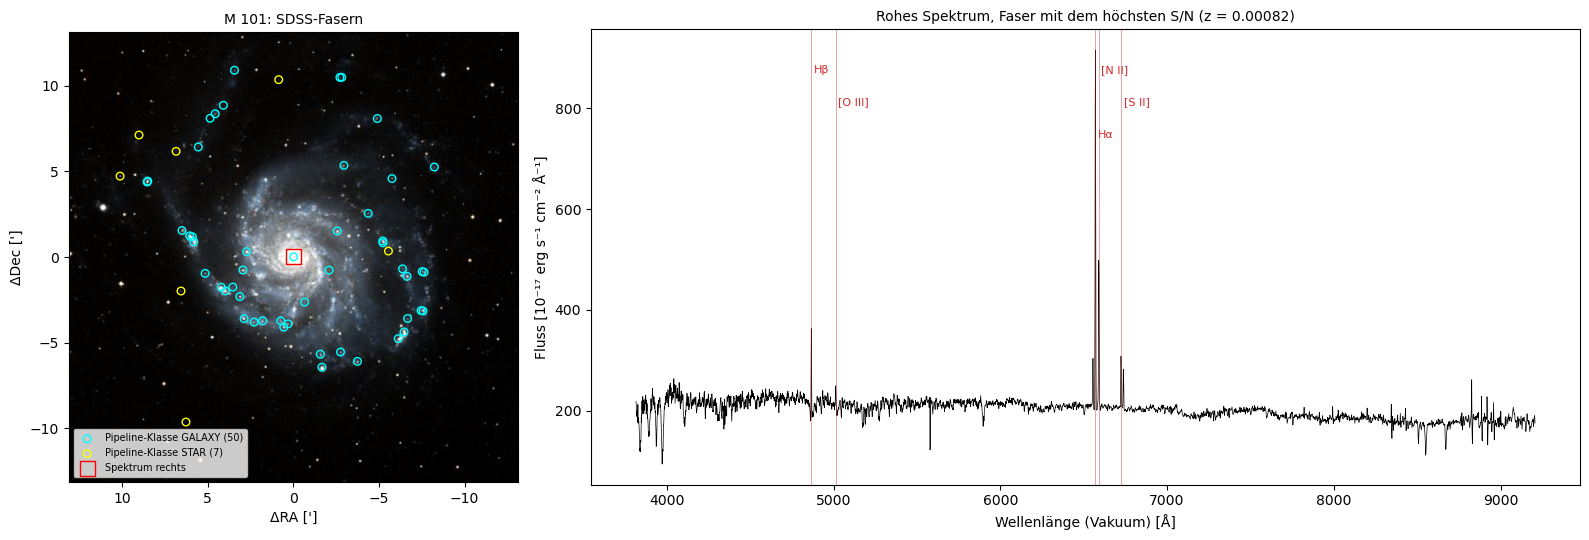

In [3]:
g = Simbad.query_tap(f'''
SELECT b.ra, b.dec, b.rvz_radvel, b.galdim_majaxis, b.galdim_minaxis, b.galdim_angle, b.morph_type
FROM basic AS b JOIN ident AS i ON i.oidref = b.oid
WHERE i.id = '{SPEC_GALAXY}' ''').to_pandas().iloc[0]
g_ra, g_dec, v_sys, g_a = g["ra"], g["dec"], g["rvz_radvel"], g["galdim_majaxis"]
g_q = g["galdim_minaxis"] / g_a if pd.notna(g["galdim_minaxis"]) else 1.0
g_pa = np.deg2rad(float(g["galdim_angle"]) if pd.notna(g["galdim_angle"]) else 0.0)
dist = Simbad.query_tap(f'''SELECT m.dist, m.unit, m.method FROM mesDistance AS m JOIN ident AS i ON i.oidref = m.oidref
                            WHERE i.id = '{SPEC_GALAXY}' ''').to_pandas()
dist["mpc"] = dist["dist"] * dist["unit"].str.strip().map({"Mpc": 1.0, "kpc": 1e-3, "pc": 1e-6})
g_dist = dist.loc[dist["method"].str.strip() != "redshift", "mpc"].median()
kpc_per_arcmin = g_dist * 1e3 * np.deg2rad(1 / 60)

# Alle Spektren in einem Kasten um die Katalogellipse, Geschwindigkeit innerhalb von 600 km/s der Galaxie,
# mit den Linienflüssen und Häufigkeiten aus dem MPA-JHU-Katalog, wo es sie gibt
r_deg = g_a / 2 / 60
query = f'''
SELECT s.specObjID, s.ra, s.dec, s.z, s.class, s.plate, s.mjd, s.fiberID, s.run2d, s.snMedian,
       l.h_alpha_flux AS mpa_Ha, l.h_beta_flux AS mpa_Hb, l.oiii_5007_flux AS mpa_OIII5007,
       l.nii_6584_flux AS mpa_NII6584, e.oh_p50 AS mpa_oh
FROM SpecObj AS s
LEFT JOIN galSpecLine AS l ON l.specObjID = s.specObjID
LEFT JOIN galSpecExtra AS e ON e.specObjID = s.specObjID
WHERE s.ra BETWEEN {g_ra - r_deg / np.cos(np.radians(g_dec))} AND {g_ra + r_deg / np.cos(np.radians(g_dec))}
  AND s.dec BETWEEN {g_dec - r_deg} AND {g_dec + r_deg}
  AND s.z BETWEEN {(v_sys - 600) / C_KMS} AND {(v_sys + 600) / C_KMS}
ORDER BY s.snMedian DESC'''
spec_list = sdss_query(query)[:MAX_SPECTRA]
spectra = SDSS.get_spectra(matches=spec_list, data_release=17)
spec_list["specObjID"] = spec_list["specObjID"].astype(str)

print(f"{SPEC_GALAXY}: Hubble-Typ {g['morph_type']}, v_sys = {v_sys:.0f} km/s, D = {g_dist:.2f} Mpc (1' = {kpc_per_arcmin:.2f} kpc), "
      f"Durchmesser {g_a:.1f}', q = {g_q:.2f}")
print(f"{len(spec_list)} SDSS-Spektren geladen; Klassen der Pipeline: "
      f"{dict(zip(*np.unique(np.asarray(spec_list['class']), return_counts=True)))}")
print(f"Mit Linienflüssen im MPA-JHU-Katalog: {np.isfinite(np.asarray(spec_list['mpa_Ha'], dtype=float)).sum()}")

# Erster Blick: Lage der Fasern und das Spektrum mit dem höchsten Signal-Rausch-Verhältnis
img_opt = hips2fits.query(hips="CDS/P/DSS2/color", width=500, height=500, ra=Angle(g_ra * u.deg), dec=Angle(g_dec * u.deg),
                          fov=Angle(1.2 * g_a * u.arcmin), projection="TAN", format="jpg")
half_g = 0.6 * g_a
dx_all = (np.asarray(spec_list["ra"]) - g_ra) * np.cos(np.radians(g_dec)) * 60     # Bogenminuten, Osten positiv
dy_all = (np.asarray(spec_list["dec"]) - g_dec) * 60
first = spectra[0][1].data
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].imshow(img_opt, extent=[half_g, -half_g, -half_g, half_g])
for cls, col in [("GALAXY", "cyan"), ("STAR", "yellow")]:
    m = np.asarray(spec_list["class"]) == cls
    axes[0].scatter(dx_all[m], dy_all[m], s=30, facecolors="none", edgecolors=col, label=f"Pipeline-Klasse {cls} ({m.sum()})")
axes[0].scatter(dx_all[0], dy_all[0], s=120, marker="s", facecolors="none", edgecolors="red", label="Spektrum rechts")
axes[0].set_xlabel("ΔRA [']")
axes[0].set_ylabel("ΔDec [']")
axes[0].set_title(f"{SPEC_GALAXY}: SDSS-Fasern", fontsize=10)
axes[0].legend(fontsize=7, loc="lower left")
axes[1].plot(10 ** first["loglam"], first["flux"], c="black", lw=0.5)
z0 = float(spec_list["z"][0])
for k, (ln, lab) in enumerate(LABEL.items()):
    axes[1].axvline(LINES[ln] * (1 + z0), color="tab:red", lw=0.6, alpha=0.5)
    axes[1].text(LINES[ln] * (1 + z0) + 15, (0.95 - 0.07 * (k % 3)) * np.nanmax(first["flux"]), lab, fontsize=8, color="tab:red")
axes[1].set_xlabel("Wellenlänge (Vakuum) [Å]")
axes[1].set_ylabel("Fluss [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
axes[1].set_title(f"Rohes Spektrum, Faser mit dem höchsten S/N (z = {z0:.5f})", fontsize=10)
fig.tight_layout()
plt.show()

* Die **Ausgabe** gibt M 101 mit 6.83 Mpc Entfernung (1′ = 1.99 kpc), 21.9′ Durchmesser und $q = 0.95$, also fast von oben. Im Kasten liegen 57 Spektren mit passender Geschwindigkeit; die Pipeline stuft 50 als Galaxie und 7 als Stern ein, und für alle gibt es Werte im MPA-JHU-Katalog.
* Das **linke Bild** zeigt die Fasern auf dem Farbbild: Die cyanen sitzen fast alle auf hellen Knoten in den Spiralarmen, den H-II-Regionen, bis weit hinaus; die gelben (Klasse STAR) liegen verstreut, auch außerhalb der Galaxie. Das rote Quadrat markiert die Faser im Zentrum.
* Das **rechte Bild** zeigt deren rohes Spektrum: ein Kontinuum aus Sternlicht mit Absorptionslinien (etwa bei 3930 und 3970 Å, Calcium), darauf Emissionslinien von Hβ, Hα, [N II] und [S II]. Die hellste Linie ist Hα; [N II] ist hier im Kern im Verhältnis zu Hα stark, [O III] fast unsichtbar.

#### **Reduktion**

##### *2. Linienfits*

Lassen sich die Linien jeder Faser mit Gaußprofilen auf einem linearen Kontinuum beschreiben, und wie genau trifft die gemeinsame Rotverschiebung die Linien? Vorher vorhersagen: Was passiert mit dem Fit, wenn der Detektor im Kern einer hellen Linie gesättigt ist?

Für jede Faser werden vier Gruppen angepasst: Hβ, [O III] 4959/5007, [N II] 6548/Hα/[N II] 6584 und [S II] 6717/6731, jede mit eigener Rotverschiebung und Breite. Liegen im Kern einer Linie maskierte Pixel (ohne gültigen Messwert), wird die Linie verworfen. Für die weiteren Diagnosen zählen nur Linien mit S/N > 3 (Theorie, Abschnitt 2).

**Hintergrund & Fachbegriffe:**
- **Maskierte Pixel:** Pixel mit der inversen Varianz null, etwa weil der Detektor gesättigt war; sie tragen keine Information.
- **Gemeinsamer Fit:** Linien eines Ions oder nahe beieinander teilen Rotverschiebung und Breite; das macht den Fit stabiler.
- **Vordergrundstern:** ein Stern der Milchstraße, der zufällig vor der Galaxie steht; seine Geschwindigkeit passt nur zufällig.

55 von 57 Spektren angepasst; 9 Linien verworfen, weil ihr Kern maskierte Pixel enthält
  Hb: in 1 Spektren
  OIII4959: in 1 Spektren
  OIII5007: in 3 Spektren
  Ha: in 4 Spektren
  Ha        mit S/N > 3:  45
  Hb        mit S/N > 3:  46
  OIII5007  mit S/N > 3:  44
  NII6584   mit S/N > 3:  47
  SII6717   mit S/N > 3:  48
  SII6731   mit S/N > 3:  46
Eigene Geschwindigkeit aus Hα minus SDSS-Rotverschiebung: Median +1.8 km/s, Streuung 5.6 km/s
Geschwindigkeiten der 43 Regionen mit Hα und [N II]: 174 bis 310 km/s (v_sys laut SIMBAD 243 km/s)
Spektren der Klasse STAR: 7, davon mit [N II]: 0; Geschwindigkeiten -399, -200, -124, -88, -6, 83, 234 km/s


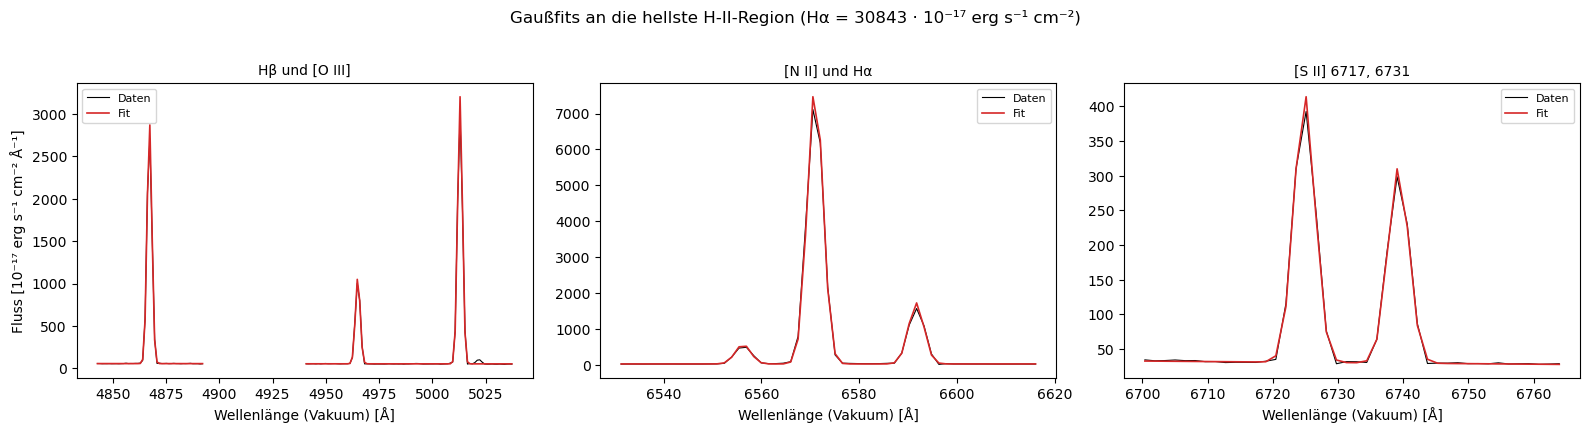

In [4]:
def fit_group(wave, flux, err, names, z0):
    # Gaußlinien mit gemeinsamer Rotverschiebung und Breite auf einem linearen Kontinuum (Theorie, Abschnitt 2)
    lam0 = np.array([LINES[ln] for ln in names])
    m = (wave > lam0.min() * (1 + z0) - 25) & (wave < lam0.max() * (1 + z0) + 25) & np.isfinite(err)
    w, f, e = wave[m], flux[m], err[m]
    def model(w, z, sig, c0, c1, *amps):
        out = c0 + c1 * (w - w.mean())
        for a, l in zip(amps, lam0):
            out = out + a * np.exp(-0.5 * ((w - l * (1 + z)) / sig) ** 2)
        return out
    p0 = [z0, 2.0, np.median(f), 0.0] + [max(f.max() - np.median(f), 1.0)] * len(names)
    lo = [z0 - 0.002, 0.5, -np.inf, -np.inf] + [0.0] * len(names)
    hi = [z0 + 0.002, 8.0, np.inf, np.inf] + [np.inf] * len(names)
    popt, pcov = curve_fit(model, w, f, p0=p0, sigma=e, absolute_sigma=True, bounds=(lo, hi), maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    sig, dsig = popt[1], perr[1]
    fluxes = {ln: popt[4 + i] * sig * np.sqrt(2 * np.pi) for i, ln in enumerate(names)}
    errs = {ln: np.sqrt((perr[4 + i] * sig) ** 2 + (popt[4 + i] * dsig) ** 2) * np.sqrt(2 * np.pi) for i, ln in enumerate(names)}
    # Liegen im Kern einer Linie (± 2 σ) Pixel ohne Daten (ivar = 0, z. B. gesättigt), schätzt der Fit
    # die Höhe nur aus den Flanken; solche Linien werden verworfen
    for l, ln in zip(lam0, names):
        core = np.abs(wave - l * (1 + popt[0])) < 2 * sig
        if (~np.isfinite(err[core])).any():
            fluxes[ln], errs[ln] = np.nan, np.nan
    return fluxes, errs, popt[0], (w, f, model(w, *popt))

rows, curves = [], {}
for sp, hdul in zip(spec_list, spectra):
    d = hdul[1].data
    wave, flux, ivar = 10 ** d["loglam"], d["flux"], d["ivar"]
    err = np.where(ivar > 0, 1 / np.sqrt(np.where(ivar > 0, ivar, 1)), np.nan)
    rec = {"specObjID": sp["specObjID"], "ra": sp["ra"], "dec": sp["dec"], "z_sdss": sp["z"], "class": sp["class"]}
    try:
        for grp in GROUPS:
            fl, er, z_fit, curve = fit_group(wave, flux, err, grp, sp["z"])
            for ln in grp:
                rec[ln], rec[ln + "_err"] = fl[ln], er[ln]
            if "Ha" in grp:
                rec["z_own"] = z_fit
            curves.setdefault(sp["specObjID"], {})[grp[-1]] = curve
    except (RuntimeError, ValueError):
        continue
    zl = hdul[3].data                                   # Linienfits der SDSS-Pipeline (SPZLINE)
    ha_pipe = zl[zl["LINENAME"] == "H_alpha"]
    rec["Ha_pipeline"] = float(ha_pipe["LINEAREA"][0]) if len(ha_pipe) else np.nan
    for col in ["mpa_Ha", "mpa_Hb", "mpa_OIII5007", "mpa_NII6584", "mpa_oh"]:
        rec[col] = float(sp[col]) if not np.ma.is_masked(sp[col]) else np.nan
    rows.append(rec)
L = pd.DataFrame(rows)

def good(*names):
    # alle genannten Linien mit S/N über SN_MIN
    return np.all([L[ln] > SN_MIN * L[ln + "_err"] for ln in names], axis=0)

L["v_own"] = L["z_own"] * C_KMS
n_masked = sum(L[ln].isna().sum() for ln in LINES)
print(f"{len(L)} von {len(spec_list)} Spektren angepasst; {n_masked} Linien verworfen, weil ihr Kern maskierte Pixel enthält")
for ln in LINES:
    if L[ln].isna().any():
        print(f"  {ln}: in {L[ln].isna().sum()} Spektren")
for ln in ["Ha", "Hb", "OIII5007", "NII6584", "SII6717", "SII6731"]:
    print(f"  {ln:9s} mit S/N > {SN_MIN:.0f}: {good(ln).sum():3d}")
gas = good("Ha", "NII6584")                          # Gas mit Metalllinien, also H-II-Regionen in der Galaxie
dv = (L.loc[gas, "z_own"] - L.loc[gas, "z_sdss"]) * C_KMS
print(f"Eigene Geschwindigkeit aus Hα minus SDSS-Rotverschiebung: Median {dv.median():+.1f} km/s, Streuung {dv.std():.1f} km/s")
print(f"Geschwindigkeiten der {gas.sum()} Regionen mit Hα und [N II]: {L.loc[gas, 'v_own'].min():.0f} bis {L.loc[gas, 'v_own'].max():.0f} km/s "
      f"(v_sys laut SIMBAD {v_sys:.0f} km/s)")
stars = L["class"] == "STAR"
print(f"Spektren der Klasse STAR: {stars.sum()}, davon mit [N II]: {(stars & gas).sum()}; Geschwindigkeiten "
      f"{', '.join(f'{v:.0f}' for v in np.sort(L.loc[stars, 'v_own']))} km/s")

best = L.loc[L["Ha"].idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, keys, title in [(axes[0], ["Hb", "OIII5007"], "Hβ und [O III]"), (axes[1], ["NII6584"], "[N II] und Hα"),
                        (axes[2], ["SII6731"], "[S II] 6717, 6731")]:
    for k in keys:
        w, f, mcurve = curves[best["specObjID"]][k]
        ax.plot(w, f, c="black", lw=0.8, label="Daten" if k == keys[0] else None)
        ax.plot(w, mcurve, c="tab:red", lw=1.2, label="Fit" if k == keys[0] else None)
    ax.set_xlabel("Wellenlänge (Vakuum) [Å]")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Fluss [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
fig.suptitle(f"Gaußfits an die hellste H-II-Region (Hα = {best['Ha']:.0f} · 10⁻¹⁷ erg s⁻¹ cm⁻²)", y=1.02)
fig.tight_layout()
plt.show()

* Das **Bild** zeigt die Fits an die hellste H-II-Region (Hα = 30 843 Einheiten): Hβ und [O III] links, [N II] und Hα in der Mitte, [S II] rechts. Die roten Fitkurven liegen fast genau auf den Daten. In dieser Region ist [O III] 5007 etwas heller als Hβ, und Hα ist etwa viereinhalbmal so hell wie [N II] 6584.
* Die **Ausgabe** zeigt: 55 von 57 Spektren lassen sich anpassen; 9 Linien werden verworfen, weil ihr Kern maskierte Pixel enthält, vor allem Hα und [O III] in den hellsten Regionen, wo der Detektor gesättigt war. Ohne diese Prüfung schätzt der Fit die Höhe aus den Flanken und liegt weit daneben.
* Die eigene Geschwindigkeit aus Hα stimmt mit der SDSS-Rotverschiebung auf $+1.8\pm5.6$ km/s überein. Die 43 Regionen mit Hα und [N II] haben 174 bis 310 km/s, also etwa ±70 km/s um die systemische Geschwindigkeit: die Rotation der fast von oben gesehenen Scheibe. Die 7 Spektren der Klasse STAR haben kein [N II] und Geschwindigkeiten von −399 bis +234 km/s; es sind Vordergrundsterne.

#### **Eigene Messung**

##### *3. Dichte und Staub*

Wie dicht ist das Gas in den H-II-Regionen, und wie viel Licht schluckt der Staub vor ihnen? Vorher vorhersagen: Liegt das Balmer-Dekrement über oder unter 2.86?

Aus dem [S II]-Verhältnis folgt mit der Formel von Sanders et al. die Elektronendichte, aus Hα/Hβ die Rötung $E(B-V)$ und die Extinktion $A_V$. Verwendet werden nur Regionen, in denen die nötigen Linien S/N > 3 haben (Theorie, Abschnitte 3 und 4).

**Hintergrund & Fachbegriffe:**
- **Elektronendichte $n_e$:** die Zahl freier Elektronen pro cm³; zum Vergleich enthält Luft etwa $10^{19}$ Moleküle pro cm³.
- **Rötung $E(B-V)$:** wie viel stärker Staub blaues als visuelles Licht schwächt, in Magnituden.
- **Perzentil:** Zwischen dem 16. und 84. Perzentil liegen die mittleren 68 % der Werte.

[S II] 6717/6731 in 42 Regionen: Median 1.398 (16.-84. Perzentil 1.31 bis 1.45)
  -> n_e ≈ 34 cm⁻³ aus dem Median; 17% der Regionen liegen über dem Grenzwert 1.45 für n_e -> 0
Hα/Hβ in 42 Regionen: Median 3.76 (ohne Staub 2.86)
  -> E(B-V) ≈ 0.28 mag, A_V ≈ 0.85 mag, also 47% des Hα-Lichts und 60% des Hβ-Lichts vom Staub geschluckt
  Regionen mit Hα/Hβ < 2.86 (unphysikalisch, Rauschen oder Absorption der Sterne unter Hβ): 0


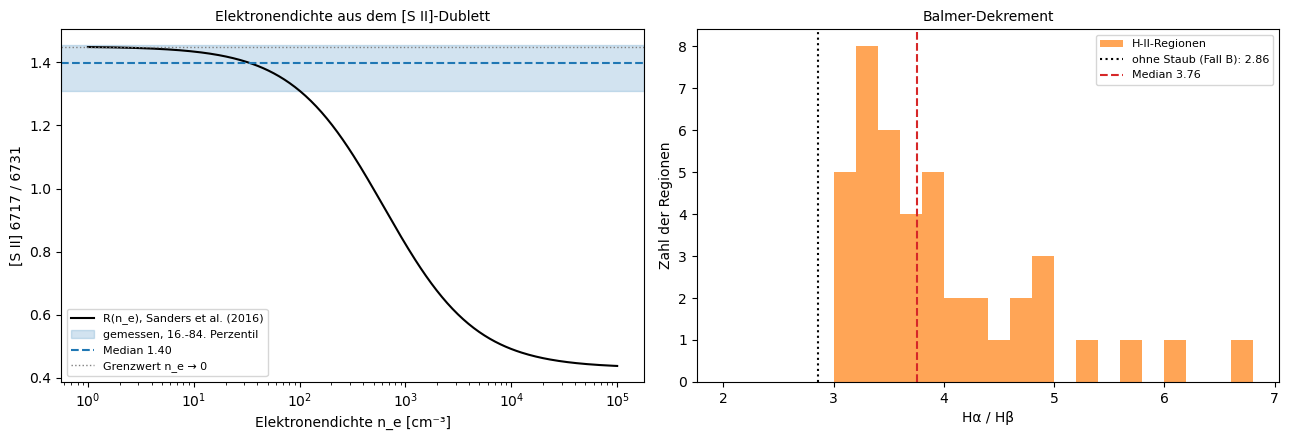

In [5]:
np.seterr(divide="ignore", invalid="ignore")                          # log von Nicht-Nachweisen -> NaN
A_SII, B_SII, C_SII = 0.4315, 2107.0, 627.1                           # Sanders et al. (2016), T = 10^4 K
def R_of_ne(ne):
    return A_SII * (B_SII + ne) / (C_SII + ne)
def ne_of_R(R):
    return (C_SII * R - A_SII * B_SII) / (A_SII - R)                  # Theorie, Abschnitt 4

L["R_SII"] = L["SII6717"] / L["SII6731"]
L["balmer"] = L["Ha"] / L["Hb"]
L["EBV"] = 2.5 / (3.61 - 2.53) * np.log10(L["balmer"] / 2.86)         # Theorie, Abschnitt 3
ok_s = good("SII6717", "SII6731", "Ha")
ok_b = good("Ha", "Hb")
R_med = L.loc[ok_s, "R_SII"].median()
R_lo, R_hi = L.loc[ok_s, "R_SII"].quantile([0.16, 0.84])
n_med = ne_of_R(R_med) if R_med < A_SII * B_SII / C_SII else 0.0
above = (L.loc[ok_s, "R_SII"] > A_SII * B_SII / C_SII).mean()
ebv_med = L.loc[ok_b, "EBV"].median()

print(f"[S II] 6717/6731 in {ok_s.sum()} Regionen: Median {R_med:.3f} (16.-84. Perzentil {R_lo:.2f} bis {R_hi:.2f})")
print(f"  -> n_e ≈ {n_med:.0f} cm⁻³ aus dem Median; {above:.0%} der Regionen liegen über dem Grenzwert 1.45 für n_e -> 0")
print(f"Hα/Hβ in {ok_b.sum()} Regionen: Median {L.loc[ok_b, 'balmer'].median():.2f} (ohne Staub 2.86)")
print(f"  -> E(B-V) ≈ {ebv_med:.2f} mag, A_V ≈ {3.1 * ebv_med:.2f} mag, also {1 - 10 ** (-0.4 * 2.53 * ebv_med):.0%} des Hα-Lichts "
      f"und {1 - 10 ** (-0.4 * 3.61 * ebv_med):.0%} des Hβ-Lichts vom Staub geschluckt")
print(f"  Regionen mit Hα/Hβ < 2.86 (unphysikalisch, Rauschen oder Absorption der Sterne unter Hβ): {(L.loc[ok_b, 'balmer'] < 2.86).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ne = np.logspace(0, 5, 300)
axes[0].semilogx(ne, R_of_ne(ne), c="black", label="R(n_e), Sanders et al. (2016)")
axes[0].axhspan(R_lo, R_hi, color="tab:blue", alpha=0.2, label="gemessen, 16.-84. Perzentil")
axes[0].axhline(R_med, color="tab:blue", ls="--", label=f"Median {R_med:.2f}")
axes[0].axhline(A_SII * B_SII / C_SII, color="grey", ls=":", lw=1, label="Grenzwert n_e → 0")
axes[0].set_xlabel("Elektronendichte n_e [cm⁻³]")
axes[0].set_ylabel("[S II] 6717 / 6731")
axes[0].set_title("Elektronendichte aus dem [S II]-Dublett", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].hist(L.loc[ok_b, "balmer"], bins=np.arange(2.0, 7.0, 0.2), color="tab:orange", alpha=0.7, label="H-II-Regionen")
axes[1].axvline(2.86, color="black", ls=":", label="ohne Staub (Fall B): 2.86")
axes[1].axvline(L.loc[ok_b, "balmer"].median(), color="tab:red", ls="--", label=f"Median {L.loc[ok_b, 'balmer'].median():.2f}")
axes[1].set_xlabel("Hα / Hβ")
axes[1].set_ylabel("Zahl der Regionen")
axes[1].set_title("Balmer-Dekrement", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Kurve $R(n_e)$ mit dem gemessenen Bereich (blau): Das [S II]-Verhältnis liegt im Median bei 1.40, fast am oberen Grenzwert 1.45 für sehr dünnes Gas. Die Kurve ist dort flach, und der Median entspricht etwa 34 Elektronen pro cm³; die Spanne der Perzentile reicht von 0 bis etwa 100 cm⁻³.
* Das **rechte Bild** zeigt das Balmer-Dekrement aller Regionen: Alle liegen über 2.86 (schwarz gepunktet), der Median bei 3.76 (rot), einige bis 6.8. Es gibt also überall Staub, in manchen Regionen viel.
* Die **Ausgabe** gibt $E(B-V)\approx0.28$ mag und $A_V\approx0.85$ mag: Der Staub schluckt etwa die Hälfte des Hα-Lichts und 60 % des Hβ-Lichts. 17 % der Regionen liegen wegen des Rauschens über dem Grenzwert 1.45; das Dublett gibt hier eher eine obere Grenze der Dichte als einen Wert.

##### *4. Das BPT-Diagramm*

Werden die Gaswolken von jungen Sternen ionisiert oder von etwas Härterem? Die H-II-Regionen von M 101 erscheinen vor den Linienverhältnissen von 20 000 SDSS-Galaxien. Vorher vorhersagen: Wo im Diagramm liegt der Kern von M 101?

Für jede Region mit allen vier Linien über S/N 3 werden $\log([\text{N II}]/\text{H}\alpha)$ und $\log([\text{O III}]/\text{H}\beta)$ berechnet und mit den Trennlinien von Kauffmann und Kewley eingeteilt; die Farbe gibt den Abstand vom Zentrum in der Scheibe (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Sequenz der Sternentstehung:** der linke Arm im BPT-Diagramm; entlang der Sequenz ändert sich vor allem die Metallizität.
- **AGN-Arm:** der rechte Arm nach oben, Galaxien mit aktivem Kern.
- **Trennlinie:** eine empirische (Kauffmann) oder aus Modellen gewonnene (Kewley) Grenze zwischen den Klassen.

M 101: 41 Regionen mit allen vier Linien über S/N 3: {'Sternentstehung': 40, 'Mischform': 1}
Vergleichsgalaxien (20,000): {'Sternentstehung': '71%', 'Mischform': '18%', 'AGN': '11%'}
Bereich der H-II-Regionen: log [N II]/Hα von -1.47 bis -0.37, log [O III]/Hβ von -0.83 bis 0.81


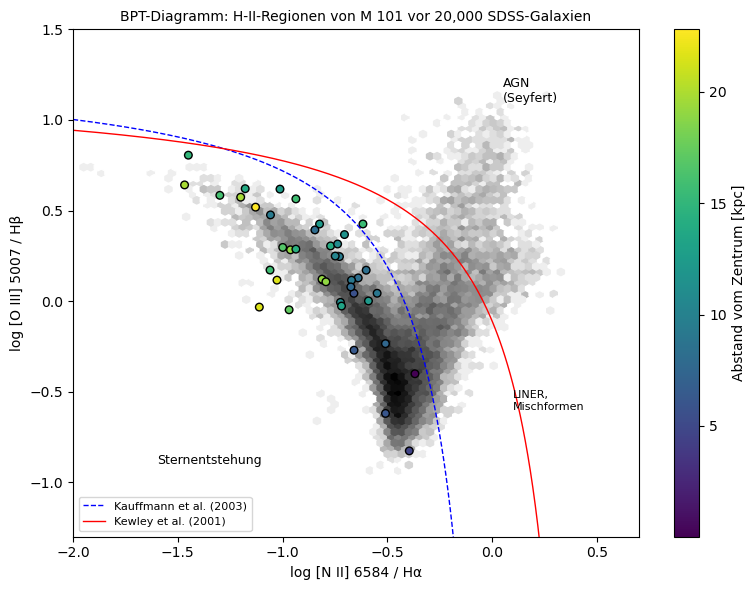

In [6]:
L["logN2"] = np.log10(L["NII6584"] / L["Ha"])
L["logO3"] = np.log10(L["OIII5007"] / L["Hb"])
def kauff(x):
    return 0.61 / (x - 0.05) + 1.30
def kewley(x):
    return 0.61 / (x - 0.47) + 1.19
bpt_ok = good("Ha", "Hb", "OIII5007", "NII6584")
below_kauff = (L["logN2"] < 0.0) & (L["logO3"] < kauff(L["logN2"]))
below_kewley = (L["logN2"] < 0.4) & (L["logO3"] < kewley(L["logN2"]))
L["bpt"] = np.where(~bpt_ok, "zu schwach", np.where(below_kauff, "Sternentstehung", np.where(below_kewley, "Mischform", "AGN")))
L["star_forming"] = L["bpt"] == "Sternentstehung"

ref = sdss_query('''SELECT TOP 20000 l.h_alpha_flux AS ha, l.h_beta_flux AS hb, l.oiii_5007_flux AS oiii, l.nii_6584_flux AS nii
FROM galSpecLine AS l WHERE l.h_alpha_flux > 5 * l.h_alpha_flux_err AND l.h_beta_flux > 5 * l.h_beta_flux_err
  AND l.oiii_5007_flux > 5 * l.oiii_5007_flux_err AND l.nii_6584_flux > 5 * l.nii_6584_flux_err
  AND l.h_alpha_flux_err > 0 AND l.h_beta_flux_err > 0''').to_pandas()
rN2, rO3 = np.log10(ref["nii"] / ref["ha"]), np.log10(ref["oiii"] / ref["hb"])
ref_class = np.where((rN2 < 0) & (rO3 < kauff(rN2)), "Sternentstehung",
                     np.where((rN2 < 0.4) & (rO3 < kewley(rN2)), "Mischform", "AGN"))

print(f"{SPEC_GALAXY}: {bpt_ok.sum()} Regionen mit allen vier Linien über S/N {SN_MIN:.0f}:",
      L.loc[bpt_ok, "bpt"].value_counts().to_dict())
print(f"Vergleichsgalaxien ({len(ref):,}):", {k: f"{v:.0%}" for k, v in pd.Series(ref_class).value_counts(normalize=True).items()})
print(f"Bereich der H-II-Regionen: log [N II]/Hα von {L.loc[bpt_ok, 'logN2'].min():.2f} bis {L.loc[bpt_ok, 'logN2'].max():.2f}, "
      f"log [O III]/Hβ von {L.loc[bpt_ok, 'logO3'].min():.2f} bis {L.loc[bpt_ok, 'logO3'].max():.2f}")

# Abstand vom Zentrum in der Scheibe (Theorie, Abschnitt 6), hier schon für die Farben gebraucht
dxs = (L["ra"] - g_ra) * np.cos(np.radians(g_dec)) * 60
dys = (L["dec"] - g_dec) * 60
L["R_arcmin"] = np.hypot(dxs * np.sin(g_pa) + dys * np.cos(g_pa), (dxs * np.cos(g_pa) - dys * np.sin(g_pa)) / g_q)
L["R_kpc"] = L["R_arcmin"] * kpc_per_arcmin

fig, ax = plt.subplots(figsize=(8, 6))
ax.hexbin(rN2, rO3, gridsize=80, extent=(-2, 0.7, -1.3, 1.5), bins="log", cmap="Greys", mincnt=1)
xx = np.linspace(-2, 0.0, 200)
ax.plot(xx, kauff(xx), "b--", lw=1, label="Kauffmann et al. (2003)")
xx2 = np.linspace(-2, 0.4, 200)
ax.plot(xx2, kewley(xx2), "r-", lw=1, label="Kewley et al. (2001)")
sc = ax.scatter(L.loc[bpt_ok, "logN2"], L.loc[bpt_ok, "logO3"], c=L.loc[bpt_ok, "R_kpc"], cmap="viridis", s=30, edgecolor="k", zorder=3)
fig.colorbar(sc, ax=ax, label="Abstand vom Zentrum [kpc]")
ax.text(-1.6, -0.9, "Sternentstehung", fontsize=9)
ax.text(0.05, 1.1, "AGN\n(Seyfert)", fontsize=9)
ax.text(0.1, -0.6, "LINER,\nMischformen", fontsize=8)
ax.set_xlim(-2, 0.7)
ax.set_ylim(-1.3, 1.5)
ax.set_xlabel("log [N II] 6584 / Hα")
ax.set_ylabel("log [O III] 5007 / Hβ")
ax.set_title(f"BPT-Diagramm: H-II-Regionen von {SPEC_GALAXY} vor {len(ref):,} SDSS-Galaxien", fontsize=10)
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

* Das **Bild** zeigt die 20 000 SDSS-Galaxien (grau) in ihrer typischen Möwenform: links die Sequenz der Sternentstehung, rechts oben der Arm der AGN. Die H-II-Regionen von M 101 (farbige Punkte) liegen alle auf dem linken Arm, unter oder knapp an den Trennlinien.
* Sie ordnen sich entlang der Sequenz nach dem Radius: innen (dunkel) rechts unten mit viel [N II] und wenig [O III], metallreich; außen (gelb-grün) links oben, metallarm mit heißerem Gas. Die Sequenz der Sternentstehung ist also vor allem eine Sequenz der Metallizität.
* Die **Ausgabe** zählt 41 Regionen mit allen vier Linien: 40 auf der Sequenz der Sternentstehung, eine knapp über der Kauffmann-Linie als Mischform. Bei den Vergleichsgalaxien sind es 71 % Sternentstehung, 18 % Mischformen und 11 % AGN. M 101 hat keinen AGN; auch der Kern zeigt Linien wie eine H-II-Region.

#### **Modell und Fit**

##### *5. Der Metallizitätsgradient*

Wie ändert sich die Sauerstoffhäufigkeit mit dem Abstand vom Zentrum, und hängt die Antwort von der Eichung ab? Vorher vorhersagen: Ist das Zentrum metallreicher als die Sonne?

Für die Regionen der Sternentstehung mit gültigem O3N2 werden die Häufigkeiten nach Pettini & Pagel aus N2 und O3N2 berechnet und Geraden gegen den Abstand in kpc angepasst (Theorie, Abschnitt 6).

**Hintergrund & Fachbegriffe:**
- **dex/kpc:** wie viele Zehnerpotenzen sich die Häufigkeit pro Kiloparsec ändert; −0.02 dex/kpc sind 4.5 % weniger Sauerstoff pro kpc.
- **Katalogradius:** der halbe Durchmesser der Galaxie laut SIMBAD, hier 21.7 kpc.
- **Streuung um die Gerade:** wie stark einzelne Regionen bei gleichem Abstand verschieden sind, teils echt, teils Messfehler.

38 Regionen mit Sternentstehung, Abstände 0.0 bis 22.8 kpc (Katalogradius 21.7 kpc)
  O3N2 : 12 + log(O/H) = 8.67 ± 0.05 -0.0204 ± 0.0039 × R[kpc], Streuung um die Gerade 0.126 dex, über den Katalogradius -0.44 dex
  N2   : 12 + log(O/H) = 8.67 ± 0.03 -0.0189 ± 0.0026 × R[kpc], Streuung um die Gerade 0.083 dex, über den Katalogradius -0.41 dex


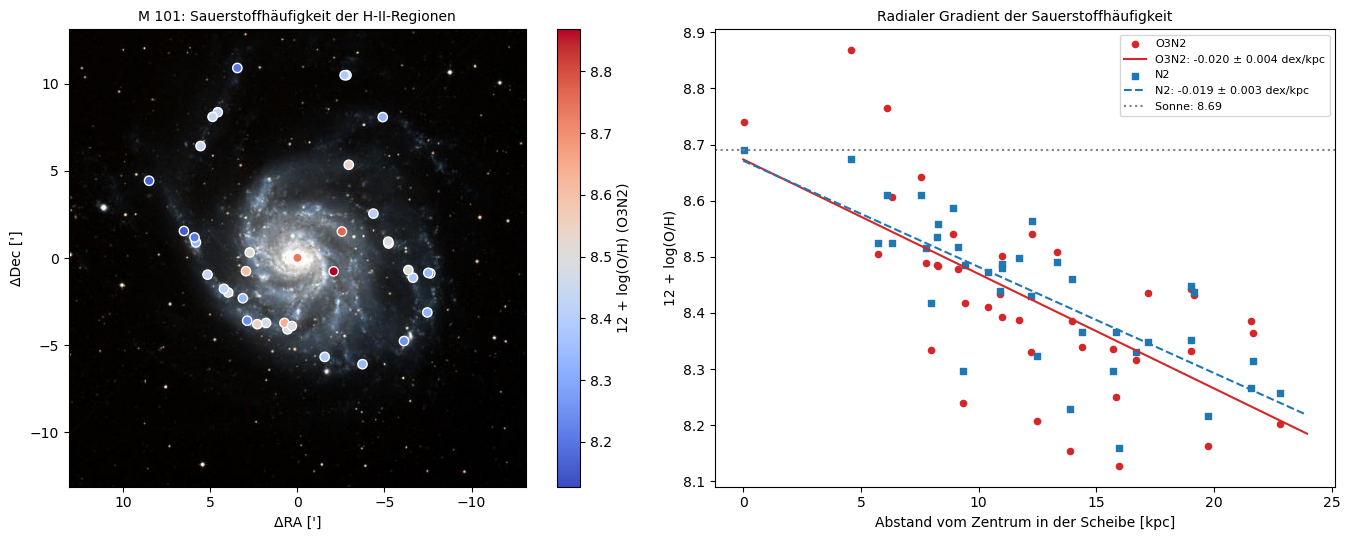

In [7]:
L["O3N2"] = L["logO3"] - L["logN2"]
L["Z_N2"] = 8.90 + 0.57 * L["logN2"]                 # Pettini & Pagel (2004)
L["Z_O3N2"] = 8.73 - 0.32 * L["O3N2"]                # Pettini & Pagel (2004)
use = L["star_forming"] & L["O3N2"].between(-1, 1.9)

def gradient(col):
    (slope, icpt), cov = np.polyfit(L.loc[use, "R_kpc"], L.loc[use, col], 1, cov=True)
    scatter = np.std(L.loc[use, col] - (icpt + slope * L.loc[use, "R_kpc"]), ddof=2)
    return slope, np.sqrt(cov[0, 0]), icpt, np.sqrt(cov[1, 1]), scatter

fits = {col: gradient(col) for col in ["Z_O3N2", "Z_N2"]}
R_disk = g_a / 2 * kpc_per_arcmin
print(f"{use.sum()} Regionen mit Sternentstehung, Abstände {L.loc[use, 'R_kpc'].min():.1f} bis {L.loc[use, 'R_kpc'].max():.1f} kpc "
      f"(Katalogradius {R_disk:.1f} kpc)")
for col, (s, ds, z0, dz0, sc) in fits.items():
    print(f"  {col[2:]:5s}: 12 + log(O/H) = {z0:.2f} ± {dz0:.2f} {s:+.4f} ± {ds:.4f} × R[kpc], Streuung um die Gerade {sc:.3f} dex, "
          f"über den Katalogradius {s * R_disk:+.2f} dex")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].imshow(img_opt, extent=[half_g, -half_g, -half_g, half_g])
sc = axes[0].scatter(dxs[use], dys[use], c=L.loc[use, "Z_O3N2"], cmap="coolwarm", s=45, edgecolor="white")
fig.colorbar(sc, ax=axes[0], label="12 + log(O/H) (O3N2)")
axes[0].set_xlabel("ΔRA [']")
axes[0].set_ylabel("ΔDec [']")
axes[0].set_title(f"{SPEC_GALAXY}: Sauerstoffhäufigkeit der H-II-Regionen", fontsize=10)
rr = np.linspace(0, L.loc[use, "R_kpc"].max() * 1.05, 50)
for col, c, mk, ls in [("Z_O3N2", "tab:red", "o", "-"), ("Z_N2", "tab:blue", "s", "--")]:
    s, ds, z0, dz0, _ = fits[col]
    axes[1].scatter(L.loc[use, "R_kpc"], L.loc[use, col], c=c, s=20, marker=mk, label=col[2:])
    axes[1].plot(rr, z0 + s * rr, c=c, ls=ls, label=f"{col[2:]}: {s:+.3f} ± {ds:.3f} dex/kpc")
axes[1].axhline(8.69, color="grey", ls=":", label="Sonne: 8.69")
axes[1].set_xlabel("Abstand vom Zentrum in der Scheibe [kpc]")
axes[1].set_ylabel("12 + log(O/H)")
axes[1].set_title("Radialer Gradient der Sauerstoffhäufigkeit", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Regionen auf dem Farbbild, gefärbt nach der Häufigkeit (O3N2): Rot (metallreich) sitzen nahe am Zentrum, blau (metallarm) weit außen in den Armen.
* Das **rechte Bild** zeigt die Häufigkeit gegen den Abstand für beide Eichungen: Sie fällt von etwa der Sonnenhäufigkeit (8.69, grau) im Zentrum auf etwa 8.2 bei 22 kpc. Beide Eichungen geben fast dieselbe Gerade, mit −0.020 ± 0.004 (O3N2) und −0.019 ± 0.003 dex/kpc (N2); N2 streut weniger (0.08 gegen 0.13 dex).
* Über den Katalogradius von 21.7 kpc fällt die Häufigkeit um 0.4 dex, also um den Faktor 2.6. Das Zentrum hat etwa Sonnenhäufigkeit, die äußeren Arme etwa ein Drittel davon.

#### **Eigene Messung gegen den Katalog**

##### *6. Vergleich mit der SDSS-Pipeline und dem MPA-JHU-Katalog*

Stimmen die eigenen Linienflüsse mit denen der SDSS-Pipeline und des MPA-JHU-Katalogs für dieselben Fasern überein, und welchen Gradienten ergibt die Häufigkeit aus dem MPA-JHU-Katalog? Vorher vorhersagen: Was ist robuster, die Flüsse oder die Verhältnisse der Linien?

Verglichen werden die eigenen Hα-Flüsse mit der SDSS-Pipeline, alle vier Linienflüsse und die Linienverhältnisse mit MPA-JHU, Faser für Faser, und die Gradienten aus den drei Häufigkeitsskalen.

**Hintergrund & Fachbegriffe:**
- **Flusseichung:** die Umrechnung des gemessenen Signals in physikalischen Fluss; SDSS und MPA-JHU eichen auf verschiedene Helligkeiten.
- **Häufigkeitsskala:** Jede Eichung (empirisch oder aus Photoionisationsmodellen wie bei Tremonti et al. 2004) hat ihren eigenen Nullpunkt.
- **Sternabsorption unter Hβ:** Die Sterne einer Region haben selbst breite Balmer-Absorptionslinien, die eine Emissionslinie schwächen, wenn man sie nicht abzieht.

Hα eigen / SDSS-Pipeline (45 Fasern): Median 0.991, Streuung 0.062
Ha        eigen / MPA-JHU (40 Fasern): Median 1.373, Streuung 0.503
Hb        eigen / MPA-JHU (41 Fasern): Median 1.329, Streuung 0.530
OIII5007  eigen / MPA-JHU (41 Fasern): Median 1.413, Streuung 0.498
NII6584   eigen / MPA-JHU (43 Fasern): Median 1.429, Streuung 0.533
Linienverhältnisse (38 Fasern): log [N II]/Hα eigen minus MPA-JHU +0.012, log [O III]/Hβ +0.025
Faktor eigen/MPA-JHU für Hα pro Faser: 1.24 bis 1.57 (10.-90. Perzentil); die Faktoren der anderen Linien derselben Faser weichen im Median ab um {'Hb': '4.4%', 'OIII5007': '2.0%', 'NII6584': '3.4%'}
Balmer-Dekrement pro Faser eigen / MPA-JHU: Median 1.046; E(B-V) eigen minus MPA-JHU: Median +0.045 mag

Gradient aus MPA-JHU (oh_p50, Tremonti et al. 2004; 34 Regionen): 12 + log(O/H) = 9.28 -0.0407 ± 0.0049 × R[kpc]
Nullpunkte im Zentrum: O3N2 8.67, N2 8.67, MPA-JHU 9.28; Sonne 8.69


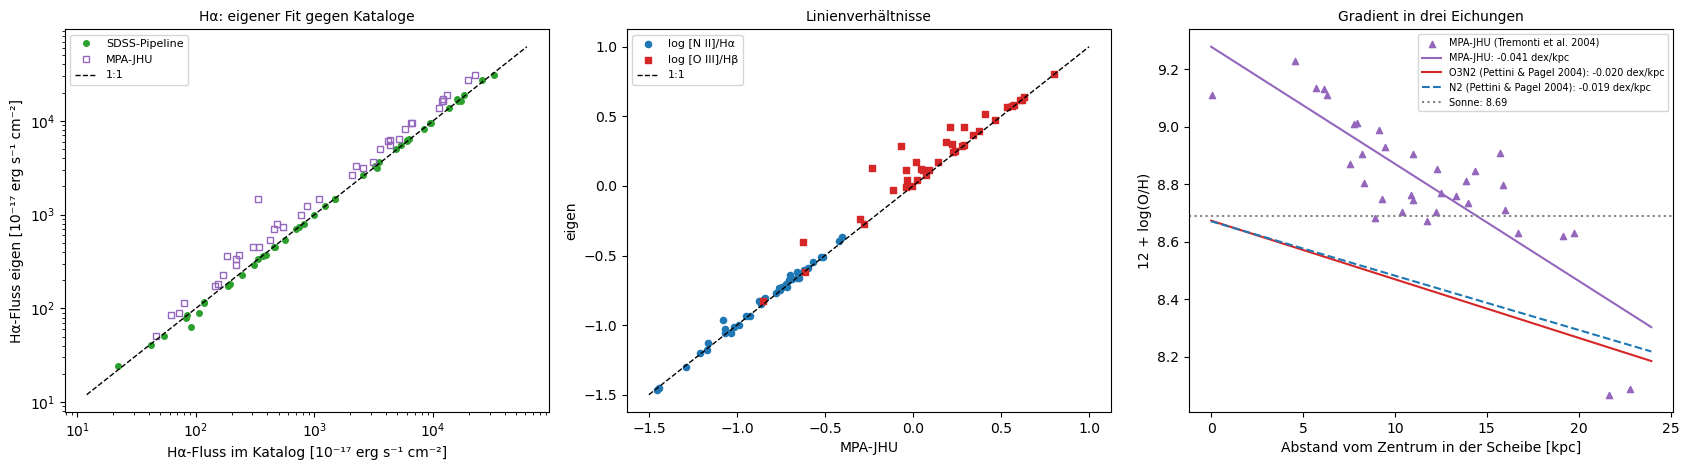

In [8]:
ok_pipe = good("Ha") & (L["Ha_pipeline"] > 0)
ratio_pipe = L.loc[ok_pipe, "Ha"] / L.loc[ok_pipe, "Ha_pipeline"]
print(f"Hα eigen / SDSS-Pipeline ({ok_pipe.sum()} Fasern): Median {ratio_pipe.median():.3f}, Streuung {ratio_pipe.std():.3f}")
for ln in ["Ha", "Hb", "OIII5007", "NII6584"]:
    m = good(ln) & (L["mpa_" + ln] > 0)
    rt = L.loc[m, ln] / L.loc[m, "mpa_" + ln]
    print(f"{ln:9s} eigen / MPA-JHU ({m.sum()} Fasern): Median {rt.median():.3f}, Streuung {rt.std():.3f}")
m_ratio = bpt_ok & (L[["mpa_Ha", "mpa_Hb", "mpa_OIII5007", "mpa_NII6584"]] > 0).all(axis=1)
mpa_N2 = np.log10(L["mpa_NII6584"] / L["mpa_Ha"])
mpa_O3 = np.log10(L["mpa_OIII5007"] / L["mpa_Hb"])
print(f"Linienverhältnisse ({m_ratio.sum()} Fasern): log [N II]/Hα eigen minus MPA-JHU {np.median((L['logN2'] - mpa_N2)[m_ratio]):+.3f}, "
      f"log [O III]/Hβ {np.median((L['logO3'] - mpa_O3)[m_ratio]):+.3f}")
# Ist der Unterschied ein Faktor pro Faser (Flusseichung) oder pro Linie (Linienfit)?
fac = pd.DataFrame({ln: L[ln] / L["mpa_" + ln] for ln in ["Ha", "Hb", "OIII5007", "NII6584"]})[m_ratio]
dev = {ln: f"{(fac[ln] / fac['Ha'] - 1).abs().median():.1%}" for ln in ["Hb", "OIII5007", "NII6584"]}
print(f"Faktor eigen/MPA-JHU für Hα pro Faser: {fac['Ha'].quantile(0.1):.2f} bis {fac['Ha'].quantile(0.9):.2f} (10.-90. Perzentil); "
      f"die Faktoren der anderen Linien derselben Faser weichen im Median ab um {dev}")
bd_mpa = (L["mpa_Ha"] / L["mpa_Hb"])[m_ratio]
print(f"Balmer-Dekrement pro Faser eigen / MPA-JHU: Median {(L.loc[m_ratio, 'balmer'] / bd_mpa).median():.3f}; "
      f"E(B-V) eigen minus MPA-JHU: Median {np.median(2.31 * np.log10(L.loc[m_ratio, 'balmer'] / bd_mpa)):+.3f} mag")

m_oh = use & (L["mpa_oh"] > 0)
(s_t, i_t), cov_t = np.polyfit(L.loc[m_oh, "R_kpc"], L.loc[m_oh, "mpa_oh"], 1, cov=True)
print(f"\nGradient aus MPA-JHU (oh_p50, Tremonti et al. 2004; {m_oh.sum()} Regionen): "
      f"12 + log(O/H) = {i_t:.2f} {s_t:+.4f} ± {np.sqrt(cov_t[0, 0]):.4f} × R[kpc]")
print(f"Nullpunkte im Zentrum: O3N2 {fits['Z_O3N2'][2]:.2f}, N2 {fits['Z_N2'][2]:.2f}, MPA-JHU {i_t:.2f}; Sonne 8.69")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
lim = [L.loc[ok_pipe, "Ha"].min() * 0.5, L.loc[ok_pipe, "Ha"].max() * 2]
axes[0].loglog(L.loc[ok_pipe, "Ha_pipeline"], L.loc[ok_pipe, "Ha"], "o", ms=4, c="tab:green", label="SDSS-Pipeline")
m = good("Ha") & (L["mpa_Ha"] > 0)
axes[0].loglog(L.loc[m, "mpa_Ha"], L.loc[m, "Ha"], "s", ms=4, mfc="none", c="tab:purple", label="MPA-JHU")
axes[0].plot(lim, lim, "k--", lw=1, label="1:1")
axes[0].set_xlabel("Hα-Fluss im Katalog [10⁻¹⁷ erg s⁻¹ cm⁻²]")
axes[0].set_ylabel("Hα-Fluss eigen [10⁻¹⁷ erg s⁻¹ cm⁻²]")
axes[0].set_title("Hα: eigener Fit gegen Kataloge", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].scatter(mpa_N2[m_ratio], L.loc[m_ratio, "logN2"], s=20, c="tab:blue", label="log [N II]/Hα")
axes[1].scatter(mpa_O3[m_ratio], L.loc[m_ratio, "logO3"], s=20, c="tab:red", marker="s", label="log [O III]/Hβ")
axes[1].plot([-1.5, 1], [-1.5, 1], "k--", lw=1, label="1:1")
axes[1].set_xlabel("MPA-JHU")
axes[1].set_ylabel("eigen")
axes[1].set_title("Linienverhältnisse", fontsize=10)
axes[1].legend(fontsize=8)
rr = np.linspace(0, L.loc[use, "R_kpc"].max() * 1.05, 50)
axes[2].scatter(L.loc[m_oh, "R_kpc"], L.loc[m_oh, "mpa_oh"], s=20, c="tab:purple", marker="^", label="MPA-JHU (Tremonti et al. 2004)")
axes[2].plot(rr, i_t + s_t * rr, c="tab:purple", label=f"MPA-JHU: {s_t:+.3f} dex/kpc")
for col, c, ls in [("Z_O3N2", "tab:red", "-"), ("Z_N2", "tab:blue", "--")]:
    s, ds, z0, dz0, _ = fits[col]
    axes[2].plot(rr, z0 + s * rr, c=c, ls=ls, label=f"{col[2:]} (Pettini & Pagel 2004): {s:+.3f} dex/kpc")
axes[2].axhline(8.69, color="grey", ls=":", label="Sonne: 8.69")
axes[2].set_xlabel("Abstand vom Zentrum in der Scheibe [kpc]")
axes[2].set_ylabel("12 + log(O/H)")
axes[2].set_title("Gradient in drei Eichungen", fontsize=10)
axes[2].legend(fontsize=7)
fig.tight_layout()
plt.show()

* Das **linke Bild** vergleicht die Hα-Flüsse: Mit der SDSS-Pipeline (grün) liegen die eigenen Werte auf der 1:1-Linie (Verhältnis 0.991, Streuung 6 %). Gegen MPA-JHU (lila Quadrate) liegen die eigenen Werte fast alle über der 1:1-Linie, im Median 1.37-mal so hoch. Das **mittlere Bild** zeigt, dass die Linienverhältnisse trotzdem auf der 1:1-Linie liegen, auf 0.01 bis 0.03 dex.
* Der Faktor zu MPA-JHU ist also für alle Linien einer Faser gleich (Abweichung 2 bis 4 %): Der Unterschied liegt in der Flusseichung des ganzen Spektrums, nicht in den Linienfits. Für Diagnosen aus Linienverhältnissen spielt er keine Rolle. Das eigene Balmer-Dekrement ist 4.6 % höher, weil MPA-JHU die Sternabsorption unter Hβ abzieht und der eigene Fit nicht.
* Das **rechte Bild** zeigt die Gradienten in drei Eichungen: MPA-JHU (Tremonti et al. 2004) liegt im Zentrum bei 9.28, 0.6 dex über Pettini & Pagel, und fällt doppelt so steil ($-0.041\pm0.005$ dex/kpc). Dieselben Spektren ergeben je nach Eichung verschiedene Nullpunkte und Steigungen; dass die Häufigkeit nach außen fällt, zeigen alle drei.

#### **Ergebnis**

Beim Lauf vom 2026-10-12 (M 101):

- **Daten:** 57 SDSS-Spektren liegen im Kasten um M 101 und innerhalb von 600 km/s der Galaxie (D = 6.83 Mpc, 1′ = 1.99 kpc, $q = 0.95$, also fast von oben gesehen). Die Pipeline stuft 50 als Galaxie und 7 als Stern ein; die 7 haben Geschwindigkeiten von −399 bis +234 km/s und kein [N II], es sind Vordergrundsterne der Milchstraße. Die Faser mit dem höchsten S/N sitzt auf dem Kern: ein Kontinuum aus Sternlicht mit Absorptionslinien, darauf deutliche Emissionslinien.
- **Linienfits:** 55 Spektren lassen sich anpassen. 9 Linien in den hellsten Regionen werden verworfen, weil ihr Kern maskierte Pixel enthält (4 × Hα, 3 × [O III] 5007): Der Detektor war dort gesättigt. Ohne diese Prüfung schätzt der Fit die Höhe aus den Flanken; in einer Region kam Hα dabei 25-mal so hell wie Hβ heraus, statt etwa dreimal. Die eigene Geschwindigkeit aus Hα weicht von der SDSS-Rotverschiebung um +1.8 ± 5.6 km/s ab. Die 43 Regionen mit Hα und [N II] haben 174 bis 310 km/s, also etwa ±70 km/s um die systemische Geschwindigkeit (243 km/s). Bei einer Neigung von nur 18° (aus $q = 0.95$) entspräche das einer Rotation von etwa 70/sin 18° ≈ 230 km/s.
- **Dichte:** Das [S II]-Verhältnis liegt im Median bei 1.40 (16.–84. Perzentil 1.31 bis 1.45), daraus $n_e \approx 34$ cm⁻³. Das Gas ist nahe am Grenzfall geringer Dichte: Die Spanne der Perzentile entspricht 0 bis 100 cm⁻³, und 17 % der Regionen liegen wegen des Rauschens sogar über dem Grenzwert. Das Dublett gibt hier also eher eine obere Grenze als einen Wert.
- **Staub:** Hα/Hβ ist im Median 3.76 statt 2.86, also $E(B-V) \approx 0.28$ mag und $A_V \approx 0.85$ mag. Der Staub schluckt etwa die Hälfte des Hα-Lichts und 60 % des Hβ-Lichts; keine Region liegt unter 2.86.
- **BPT:** Von 41 Regionen mit allen vier Linien liegen 40 auf der Sequenz der Sternentstehung, eine knapp über der Kauffmann-Linie. Die Regionen ordnen sich entlang der Sequenz nach dem Radius: innen rechts unten (viel [N II], wenig [O III], metallreich), außen links oben (metallarm, heißeres Gas). Ein AGN-Spektrum gibt es nicht; der Kern zeigt Linien wie eine H-II-Region.
- **Gradient:** Aus 38 Regionen zwischen 0 und 22.8 kpc folgt mit O3N2 $12 + \log(\text{O/H}) = 8.67 - (0.020 \pm 0.004) \cdot R/\text{kpc}$ (Streuung 0.13 dex), mit N2 $-0.019 \pm 0.003$ dex/kpc (Streuung 0.08 dex). Das Zentrum hat etwa die Häufigkeit der Sonne (8.69), über den Katalogradius von 21.7 kpc fällt sie um 0.4 dex, also um den Faktor 2.6.
- **SDSS-Pipeline:** Die eigenen Hα-Flüsse stimmen mit der Pipeline auf 1 % überein (Verhältnis 0.991, Streuung 6 %).
- **MPA-JHU:** Die eigenen Flüsse sind im Median 1.37-mal so hoch (10.–90. Perzentil 1.24 bis 1.57), aber innerhalb einer Faser ist der Faktor für alle Linien gleich (Abweichung 2–4 %), und die Linienverhältnisse stimmen auf 0.01 bis 0.03 dex. Der Unterschied liegt also in der Flusseichung des ganzen Spektrums, nicht in den Linienfits: Die SDSS-Pipeline eicht seit DR6 auf PSF-Helligkeiten, also einschließlich des Lichts, das wegen des Seeings an der Faser vorbeigeht; MPA-JHU skaliert jedes Spektrum auf die Helligkeit in der Faser aus der Photometrie, die innerhalb einer hellen Galaxie unsicher ist. Für Diagnosen aus Linienverhältnissen spielt das keine Rolle. Das eigene Balmer-Dekrement ist pro Faser um 4.6 % höher ($E(B-V)$ um 0.045 mag), weil MPA-JHU das Sternspektrum mit seiner Absorption unter Hβ abzieht und der eigene Fit nicht.
- **Häufigkeitsskalen:** Die Häufigkeit von MPA-JHU (Tremonti et al. 2004, aus Photoionisationsmodellen) liegt im Zentrum bei 9.28, 0.6 dex über Pettini & Pagel, und ihr Gradient ist doppelt so steil ($-0.041 \pm 0.005$ dex/kpc). Dieselben Spektren ergeben je nach Eichung verschiedene Nullpunkte und Steigungen; dass die Häufigkeit nach außen fällt, zeigen alle drei.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Eine andere Galaxie:** `SPEC_GALAXY = "M 33"` oder `"M 51"`. Vergleiche die Gradienten in dex/kpc und in dex pro Katalogradius. *(Vorhersage: In dex pro Scheibenradius sind die Gradienten ähnlicher als in dex/kpc.)*
2. **Strengerer Schnitt:** `SN_MIN = 10`. Wie viele Regionen bleiben, und wird die Streuung um den Gradienten kleiner?
3. **Absorption unter Hβ:** Die jungen Sterne einer H-II-Region haben selbst breite Balmer-Absorptionslinien, die das lineare Kontinuum nicht erfasst. Ergänze im Fit für Hβ eine breite Gaußlinie mit negativer Höhe (σ etwa 15 Å). *(Vorhersage: Hβ wird um einige Prozent heller, das Balmer-Dekrement und E(B−V) werden kleiner.)*
4. **Geschwindigkeitsfeld:** Trage `v_own` gegen die Position auf. *(Vorhersage: Eine Seite der Scheibe kommt auf uns zu, die andere läuft weg; der Unterschied ist wegen der kleinen Neigung nur etwa ±70 km/s, und die Linie ohne Geschwindigkeitsunterschied liegt entlang der kleinen Achse.)*
5. **Grenzwert der Dichte:** Wie ändert sich das Ergebnis für $n_e$, wenn die Temperatur 8000 statt 10 000 K ist? (Die Parameter von Sanders et al. gelten für 10 000 K; die Dichte skaliert ungefähr mit $\sqrt{T}$.)

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist eine H-II-Region, und warum zeigt sie, wo Sterne entstehen?</summary>

Eine Gaswolke, deren Wasserstoff von jungen O- und B-Sternen vollständig ionisiert wird, etwa 10 000 K heiß. Sie leuchtet nur, solange diese Sterne leben, einige Millionen Jahre.
</details>

<details><summary>2. Was unterscheidet Rekombinationslinien von verbotenen Linien?</summary>

Rekombinationslinien wie Hα entstehen, wenn ein Elektron eingefangen wird und nach unten kaskadiert; ihre Verhältnisse legt die Atomphysik fest. Verbotene Linien wie [O III] entstehen durch Stoßanregung langlebiger Zustände, die nur im sehr dünnen Gas strahlen.
</details>

<details><summary>3. Wie misst man mit dem Balmer-Dekrement den Staub?</summary>

Ohne Staub ist Hα/Hβ = 2.86. Staub schwächt Hβ stärker als Hα; aus dem gemessenen Verhältnis folgt $E(B-V)$. In M 101 ist es im Median 3.76, also $A_V\approx0.85$ mag.
</details>

<details><summary>4. Warum misst das [S II]-Dublett die Elektronendichte, und warum hier nur schlecht?</summary>

Die beiden Niveaus zerfallen verschieden schnell; bei höherer Dichte regen Stöße das langsamere vorher ab, und das Verhältnis sinkt von 1.45 auf 0.43. In M 101 liegt es bei 1.40, nahe dem Grenzwert für dünnes Gas, wo die Kurve flach ist; das ergibt eher eine obere Grenze (etwa 34 cm⁻³).
</details>

<details><summary>5. Wie unterscheidet das BPT-Diagramm Sternentstehung von einem AGN?</summary>

Es trägt [O III]/Hβ gegen [N II]/Hα auf. Das harte Spektrum eines AGN heizt eine ausgedehnte teilionisierte Zone mit viel [N II] und [O III]; AGN liegen deshalb rechts oben, Regionen mit Sternentstehung auf dem linken Arm.
</details>

<details><summary>6. Warum ist die Sequenz der Sternentstehung im BPT-Diagramm eine Sequenz der Metallizität?</summary>

Metallreiches Gas kühlt besser und ist kälter, [O III] wird schwächer, und mehr Stickstoff macht [N II] stärker. In M 101 liegen die inneren, metallreichen Regionen rechts unten, die äußeren links oben.
</details>

<details><summary>7. Wie bestimmt man die Sauerstoffhäufigkeit aus starken Linien, und wie verlässlich ist das?</summary>

Mit empirischen Eichungen wie N2 oder O3N2 (Pettini & Pagel 2004), die an Regionen mit direkt gemessener Temperatur gewonnen wurden. Die Nullpunkte verschiedener Eichungen unterscheiden sich um bis zu 0.7 dex; Unterschiede innerhalb einer Galaxie sind verlässlicher.
</details>

<details><summary>8. Was zeigt der Metallizitätsgradient von M 101?</summary>

Die Häufigkeit fällt um etwa 0.02 dex pro kpc, von Sonnenhäufigkeit im Zentrum auf etwa ein Drittel in den äußeren Armen. Das passt zu Scheiben, die von innen nach außen gewachsen sind.
</details>

<details><summary>9. Warum stimmen die eigenen Flüsse nicht mit MPA-JHU überein, die Linienverhältnisse aber schon?</summary>

Der Faktor (im Median 1.37) ist für alle Linien einer Faser gleich, liegt also in der Flusseichung des ganzen Spektrums und nicht in den Linienfits. Verhältnisse von Linien hängen von dieser Eichung nicht ab.
</details>

<details><summary>10. Warum wurden einige Linien verworfen, und was wäre ohne diese Prüfung passiert?</summary>

In den hellsten Regionen war der Detektor im Kern von Hα oder [O III] gesättigt, die Pixel sind maskiert. Der Fit schätzt die Höhe dann nur aus den Flanken; in einer Region kam Hα so 25-mal so hell wie Hβ heraus statt etwa dreimal.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Direkte Methode:** Die schwache Linie [O III] 4363 Å gibt mit [O III] 5007 Å die Elektronentemperatur und damit Häufigkeiten ohne empirische Eichung (`pyneb`). In metallreichen Regionen ist sie oft zu schwach; dann helfen gestapelte Spektren.
- **Photoionisationsmodelle** (Cloudy, MAPPINGS) statt empirischer Eichungen, mit Ionisationsparameter und Härte des Sternspektrums als freien Größen.
- **Integralfeldspektroskopie** (MaNGA, MUSE): Karten von Häufigkeit, Dichte, Extinktion und Geschwindigkeit über die ganze Scheibe statt einzelner Fasern, mit der Trennung von H-II-Regionen und diffusem ionisiertem Gas.
- **Gradienten vieler Galaxien:** In Einheiten des Scheibenradius haben Spiralgalaxien ähnliche Gradienten; Abweichungen zeigen Balken, Wechselwirkungen oder einströmendes Gas.
- **Die Masse-Metallizitäts-Beziehung** aus den Spektren der Zentren von Hunderttausenden SDSS-Galaxien (MPA-JHU).

#### **Referenzen**

- Baldwin, J. A., Phillips, M. M. & Terlevich, R. (1981): *Classification parameters for the emission-line spectra of extragalactic objects*, PASP 93, 5.
- Kewley, L. J. et al. (2001): *Theoretical modeling of starburst galaxies*, ApJ 556, 121.
- Kauffmann, G. et al. (2003): *The host galaxies of active galactic nuclei*, MNRAS 346, 1055.
- Pettini, M. & Pagel, B. E. J. (2004): *[O III]/[N II] as an abundance indicator at high redshift*, MNRAS 348, L59.
- Sanders, R. L. et al. (2016): *The MOSDEF survey: electron density and ionization parameter at z ~ 2.3*, ApJ 816, 23.
- Cardelli, J. A., Clayton, G. C. & Mathis, J. S. (1989): *The relationship between infrared, optical, and ultraviolet extinction*, ApJ 345, 245.
- Osterbrock, D. E. & Ferland, G. J. (2006): *Astrophysics of Gaseous Nebulae and Active Galactic Nuclei*, 2. Auflage, University Science Books.
- Asplund, M. et al. (2009): *The chemical composition of the Sun*, ARA&A 47, 481.
- Tremonti, C. A. et al. (2004): *The origin of the mass-metallicity relation*, ApJ 613, 898.
- Brinchmann, J. et al. (2004): *The physical properties of star-forming galaxies in the low-redshift Universe*, MNRAS 351, 1151.
- Kewley, L. J. & Ellison, S. L. (2008): *Metallicity calibrations and the mass-metallicity relation for star-forming galaxies*, ApJ 681, 1183.
- Abdurro'uf et al. (2022): *The Seventeenth Data Release of the Sloan Digital Sky Surveys*, ApJS 259, 35.